# 07 · Multiple regression and conditional comparisons

Multiple regression estimates a response using several predictors together. Its coefficients describe conditional relationships within the specified model. Adding predictors improves or preserves training fit, but it can make estimates unstable and future predictions worse.

```mermaid
flowchart TD
    A[Build a design matrix] --> B[Estimate coefficients jointly]
    B --> C[Interpret conditional effects]
    C --> D[Compare nested models]
    D --> E[Check collinearity and residuals]
    E --> F[Evaluate new-data prediction]
```

**Learning route:** model → coding → fitting → nested tests → stability → validation. Prerequisites: [simple regression](../06_Linear_Regression/06_Linear_Regression.md). Matrix notation is introduced in [AA](../AA_Prerequisite/AA_Prerequisite.md).

## 1. From a line to a plane and beyond

With $p$ predictor columns and an intercept,

$$Y_i=\beta_0+\beta_1x_{i1}+\cdots+\beta_px_{ip}+\varepsilon_i.$$

Two numerical predictors define a plane for the conditional mean. More predictors require no new fitting principle: minimize the squared residuals. In matrix notation, $\mathbf y=X\boldsymbol\beta+\boldsymbol\varepsilon$, where the first column of $X$ is ones. Let $K=p+1$ count **all** coefficients, including the intercept.

If $X$ has full column rank, the OLS solution is theoretically $(X^TX)^{-1}X^T\mathbf y$. In numerical work, use a least-squares solver based on QR or singular-value decomposition rather than explicitly computing an inverse. Full column rank means no predictor column can be exactly reconstructed from the others.

Counting observations is not enough. Even with 1,000 rows, including both mass in kilograms and mass in grams creates exact dependence. Unique coefficients require rank $K$; estimating classical residual variance also requires $n>K$. Adequate practical sample size usually requires considerably more than the minimum.

## 2. An original worked example with a categorical predictor

A workshop records preparation time for batches. Let $x$ be batch size centered at five items, and $z$ indicate a protective coating: 0 for uncoated and 1 for coated. Use this deliberately balanced teaching dataset:

| Batch size | Centered $x$ | Coating $z$ | Times, minutes |
|---:|---:|---:|---|
| 4 | -1 | 0 | 7, 9 |
| 4 | -1 | 1 | 10, 12 |
| 6 | 1 | 0 | 11, 13 |
| 6 | 1 | 1 | 14, 16 |

Fit $Y=\beta_0+\beta_1x+\beta_2z+\varepsilon$. The fitted equation is

$$\hat y=10+2x+3z.$$

For batches of the same size, coated batches have a fitted mean three minutes higher. Within either coating category, an extra item is associated with two additional minutes. The intercept is ten minutes for an uncoated batch of five items. Centering makes this a meaningful reference rather than a hypothetical batch of zero items.

Residuals are $-1,+1$ in each row of the table, so $RSS_F=8$. There are $n=8$ observations and $K_F=3$ coefficients, giving residual variance estimate $8/(8-3)=1.6$.

![Conditional fitted lines for coated and uncoated batches](figure/conditional_fit.png)

**Notebook setup.** Run all cells from top to bottom. Figures are saved in this chapter's `figure/` folder. Restart the kernel and run all after changing a simulation. See the repository README for installation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Works when Jupyter starts in either this chapter or the repository root.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts" / "build_notebooks.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned course repository.")
FIGURE_DIR = ROOT / '07_Multiple_Regression' / "figure"
FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110,
    "font.size": 11, "axes.titlesize": 14, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#087E8B", "#D55E00", "#7251A2", "#4477AA"]),
    "savefig.facecolor": "white", "axes.facecolor": "#FAFBFC",
})
TEAL, ORANGE, PURPLE = "#087E8B", "#D55E00", "#7251A2"

def save_figure(fig, name):
    """Save the exact figure used by Markdown and display it in the notebook."""
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    display(fig)
    plt.close(fig)

print("All datasets in this notebook are synthetic teaching examples.")


All datasets in this notebook are synthetic teaching examples.


,term,estimate,SE,p
0,Intercept at size 5,10.0,0.632456,0.000018
1,Centered size,2.0,0.447214,0.006566
2,Coated,3.0,0.894427,0.020238


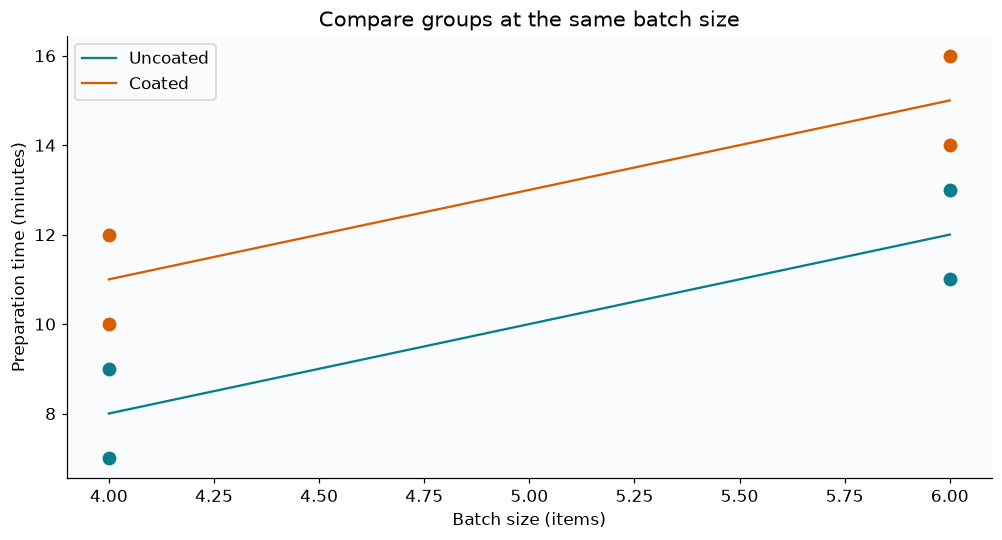

In [2]:
import statsmodels.api as sm
x = np.repeat([-1.,1.],4)
z = np.tile(np.repeat([0.,1.],2),2)
y = 10+2*x+3*z+np.tile([-1.,1.],4)
design = np.column_stack([np.ones(8),x,z])
full = sm.OLS(y,design).fit()
reduced = sm.OLS(y,design[:,:2]).fit()
manual_coefficients = np.linalg.lstsq(design,y,rcond=None)[0]
assert np.allclose(manual_coefficients,[10,2,3])
assert np.isclose(full.ssr,8) and np.isclose(reduced.ssr,26)
display(pd.DataFrame({"term":["Intercept at size 5","Centered size","Coated"],
                      "estimate":full.params,"SE":full.bse,"p":full.pvalues}))
fig, ax = plt.subplots(layout="constrained")
for group,color in [(0,TEAL),(1,ORANGE)]:
    mask = z==group
    ax.scatter(x[mask]+5,y[mask],color=color,s=65)
    grid = np.linspace(-1,1,60)
    ax.plot(grid+5,full.predict(np.column_stack([np.ones(60),grid,np.full(60,group)])),
            color=color,label="Coated" if group else "Uncoated")
ax.set(xlabel="Batch size (items)",ylabel="Preparation time (minutes)",title="Compare groups at the same batch size")
ax.legend()
save_figure(fig,"conditional_fit")

For a three-category predictor, use two indicator columns plus the intercept. Including all three indicators and an intercept creates the identity “intercept = sum of indicators” and loses rank. Changing the reference category changes coefficient labels and meanings, but not the fitted values of the same model.

## 3. “Holding other variables fixed” needs a model

In the additive model above, changing $x$ by one with $z$ fixed changes the fitted mean by $\beta_1$. This is a conditional association. It differs from a one-predictor regression when the omitted predictor is associated with both the included predictor and the response.

Adjustment is not automatically causal. An omitted common cause can leave confounding; conditioning on variables caused by treatment or on selection mechanisms can introduce other biases. Choose variables using the question and data-generating process, not just a rule that more adjustment is always better.

An **interaction** allows one relationship to vary with another predictor:

$$E[Y\mid x,z]=\beta_0+\beta_1x+\beta_2z+\beta_3xz.$$

Now the slope is $\beta_1$ for $z=0$ and $\beta_1+\beta_3$ for $z=1$. The group difference at a specified $x$ is $\beta_2+\beta_3x$. There is no single constant group effect. Keep the lower-order terms when adding an interaction unless the scientific model specifically justifies a constraint.

The notebook evaluates an example equation $10+2x+3z+xz$ to show how the group difference changes from 2 to 3 to 4 minutes as centered $x$ changes from $-1$ to 0 to 1. This is a specified illustration, not an interaction inferred from the eight-row additive dataset.

In [3]:
rows = []
for centered_size in [-1,0,1]:
    base = 10+2*centered_size
    coated = base+3+centered_size
    rows.append([centered_size,base,coated,coated-base])
display(pd.DataFrame(rows,columns=["centered_size","uncoated_mean","coated_mean","group_difference"]))

,centered_size,uncoated_mean,coated_mean,group_difference
0,-1,8,10,2
1,0,10,13,3
2,1,12,16,4


## 4. Compare nested models on identical observations

A reduced model is **nested** in a full model when setting selected full-model coefficients to zero produces the reduced model. Refit both models separately. Do not delete a term from a fitted full-model equation while retaining all its other coefficients; the remaining optimum can change.

For nested OLS models fit to the same response and rows, with $K_R<K_F$,

$$F=\frac{(RSS_R-RSS_F)/(K_F-K_R)}{RSS_F/(n-K_F)}.$$

Under the classical independent, homoscedastic normal-error model and the null that all added coefficients are zero, this has an $F_{K_F-K_R,n-K_F}$ distribution. The numerator measures improvement per added coefficient. The denominator estimates unexplained error variance from the full model.

In our example, the reduced model excludes coating. Its RSS is 26, compared with 8 for the full model. Therefore,

$$F=\frac{(26-8)/(3-2)}{8/(8-3)}=11.25,$$

with degrees of freedom $(1,5)$ and p-value about 0.020. This tests the coating coefficient conditional on batch size. With a single added coefficient, $F=t^2$ under the same variance assumptions.

In [4]:
partial_f = ((reduced.ssr-full.ssr)/1)/(full.ssr/full.df_resid)
partial_p = stats.f.sf(partial_f,1,full.df_resid)
library_f,library_p,df_difference = full.compare_f_test(reduced)
assert np.isclose(partial_f,11.25) and np.isclose(partial_f,full.tvalues[2]**2)
assert np.isclose(partial_p,library_p)
print(f"Partial F={partial_f:.4f}, df=(1,5), p={partial_p:.5f}")
print(f"R²={full.rsquared:.5f}, adjusted R²={full.rsquared_adj:.5f}")

Partial F=11.2500, df=(1,5), p=0.02024
R²=0.86207, adjusted R²=0.80690


The **overall** F-test compares all predictor coefficients to zero against an intercept-only model. It can reject even when some individual coefficients are imprecise. Non-nested formulas, different response transformations, or different rows due to missing data do not meet the conditions for this simple RSS comparison.

## 5. $R^2$ and adjusted $R^2$

Because the full model can set extra coefficients to zero, its minimized training RSS cannot increase. Consequently training $R^2$ cannot decrease. Random noise predictors can absorb chance features of the training data even when they have no real predictive relationship.

For an intercept model, adjusted $R^2$ is

$$\bar R^2=1-\frac{RSS/(n-K)}{TSS/(n-1)}.$$

It compares residual variation per remaining degree of freedom with the mean-only estimate. In our example, $TSS=58$, $R^2=1-8/58\approx0.8621$, and adjusted $R^2\approx0.8069$. It may decrease when unnecessary predictors are added and may be negative. It is a penalized training summary, not a substitute for evaluating new data or a guarantee of selecting the true model.

![Training and test error after adding irrelevant predictors](figure/overfitting.png)

,predictors,train_RMSE,test_RMSE,R2,adjusted_R2
0,2,0.938253,1.007020,0.826561,0.817186
1,5,0.882230,1.058473,0.846654,0.824104
2,10,0.853285,1.100576,0.856552,0.807087
3,20,0.747297,1.239772,0.889974,0.774158
4,30,0.501878,1.823682,0.950375,0.784957


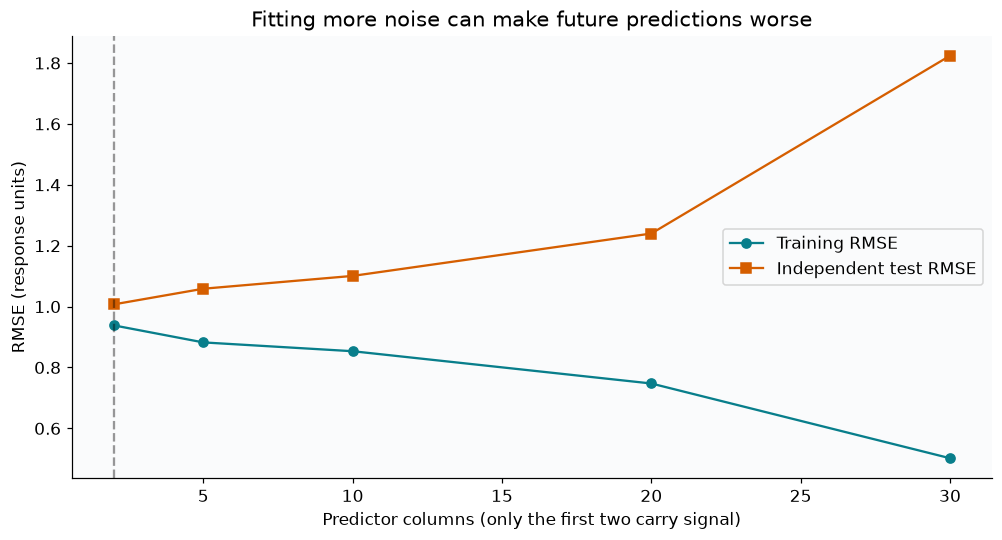

In [5]:
rng = np.random.default_rng(707)
train_x = rng.normal(size=(40,30))
test_x = rng.normal(size=(3000,30))
train_y = 4+2*train_x[:,0]-train_x[:,1]+rng.normal(size=40)
test_y = 4+2*test_x[:,0]-test_x[:,1]+rng.normal(size=3000)
rows = []
for predictors in [2,5,10,20,30]:
    fit = sm.OLS(train_y,sm.add_constant(train_x[:,:predictors])).fit()
    test_prediction = fit.predict(sm.add_constant(test_x[:,:predictors]))
    rows.append([predictors,np.sqrt(np.mean(fit.resid**2)),
                 np.sqrt(np.mean((test_y-test_prediction)**2)),fit.rsquared,fit.rsquared_adj])
scores = pd.DataFrame(rows,columns=["predictors","train_RMSE","test_RMSE","R2","adjusted_R2"])
assert np.all(np.diff(scores.train_RMSE)<=1e-10)
display(scores)
fig, ax = plt.subplots(layout="constrained")
ax.plot(scores.predictors,scores.train_RMSE,"o-",label="Training RMSE")
ax.plot(scores.predictors,scores.test_RMSE,"s-",label="Independent test RMSE")
ax.axvline(2,color="black",ls="--",alpha=.4)
ax.set(xlabel="Predictor columns (only the first two carry signal)",ylabel="RMSE (response units)",title="Fitting more noise can make future predictions worse")
ax.legend()
save_figure(fig,"overfitting")

The simulation has two true predictors. Extra columns are independent noise, and the test sample is generated separately. Training error decreases as noise variables are added, while test error can worsen. A particular test curve can wobble; the lesson is to measure generalization rather than infer it from training fit. If model choices use a validation set, keep a final test set untouched or use an appropriate nested validation design.

## 6. Collinearity and coefficient uncertainty

If two predictors move almost together, the data contain few comparisons where one changes while the other stays fixed. Their separate slopes become hard to identify even if their combined prediction is accurate. Coefficients may be large, uncertain, or sensitive to small data changes.

The **variance inflation factor** for predictor $j$ is $VIF_j=1/(1-R_j^2)$, where $R_j^2$ comes from regressing that predictor on the other predictors with an intercept. It describes variance inflation relative to an orthogonal design under the homoscedastic model. A high VIF is a diagnostic, not a universal instruction to delete a predictor.

The notebook contrasts an ordinary design with one containing a nearly duplicated predictor, then checks the exact rank deficiency created by a perfect duplicate. Centering can aid interpretation and reduce some numerical issues; it does not separate truly redundant measurements. Ridge regression is one possible predictive extension, but changes the estimation method and is beyond this chapter.

In [6]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
rng = np.random.default_rng(708)
a = rng.normal(size=100)
b = a+rng.normal(0,.03,100)
X_near = sm.add_constant(np.column_stack([a,b]))
X_exact = sm.add_constant(np.column_stack([a,1000*a]))
print("VIFs for nearly duplicated predictors:",[variance_inflation_factor(X_near,j) for j in [1,2]])
print("Exact duplicate design: columns =",X_exact.shape[1],"rank =",np.linalg.matrix_rank(X_exact))
assert np.linalg.matrix_rank(X_exact)==2

VIFs for nearly duplicated predictors: [np.float64(1267.1997412561748), np.float64(1267.1997412561748)]
Exact duplicate design: columns = 3 rank = 2


Continue checking residuals, leverage, influence, and collection-order dependence as in Chapter 6. A two-dimensional residual plot is still useful when a high-dimensional fitted surface cannot be shown directly.

## 7. Practice

1. A reduced model has RSS 120 and $K_R=2$. A full model on the same 30 rows has RSS 90 and $K_F=4$. Calculate the partial F statistic and its degrees of freedom.
2. Interpret $\hat y=5+2x-3z+4xz$ at $z=0$ and $z=1$.
3. An analyst adds ten independent random columns and sees training $R^2$ increase. Does that establish a better model?
4. Why can including Celsius and Fahrenheit temperatures together with an intercept make coefficients nonunique?
5. What changes in the eight-row example if the reference group changes from uncoated to coated?

## 8. Worked answers

1. $F=[(120-90)/2]/[90/26]=13/3\approx4.333$, with $(2,26)$ degrees of freedom. The upper-tail probability is calculated in the notebook.
2. At $z=0$, $\hat y=5+2x$. At $z=1$, $\hat y=2+6x$. The group difference is $-3+4x$, so “the effect of $z$ is -3” is only correct at $x=0$.
3. No. This is expected from greater fitting flexibility. Examine model purpose, uncertainty, assumptions, and independent validation.
4. $F=32+1.8C$ is an exact linear combination of the intercept and Celsius column. The design matrix cannot have full column rank.
5. With $w=1-z$, the equation becomes $\hat y=13+2x-3w$. Predictions remain identical; the intercept and group contrast now use coated batches as reference.

In [7]:
exercise_f = ((120-90)/(4-2))/(90/(30-4))
assert np.isclose(exercise_f,13/3)
print("Practice 1: F =",exercise_f,"p =",stats.f.sf(exercise_f,2,26))
assert np.allclose(10+2*x+3*z,13+2*x-3*(1-z))

Practice 1: F = 4.333333333333333 p = 0.023757264018058787


## References and next step

Reading connection: Starmer (2026), Chapter 7, [SQ](../Reference.md#sq-statquest). Matrix fitting: [NumPy least squares](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html). Model comparisons: [statsmodels compare_f_test](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.compare_f_test.html). Conditional interpretation, interactions, and held-out experiments extend the reading.

Next: [08 · t-tests](../08_T-test_for_Testing_the_Differences/08_T-test_for_Testing_the_Differences.md).